# British Airways Customer Booking Analysis

### In this project, I developed a predictive model using British Airways customer booking data to identify key behaviors that signal whether a customer will complete a holiday booking. Through structured data preparation and machine learning, I evaluated model performance and analyzed the influence of individual variables. The goal was not only to forecast booking outcomes but also to generate actionable insights that British Airways could use to improve customer engagement, optimize marketing strategies, and increase booking conversions.

### This project analyzed 50,000 customer booking records to understand what drives booking completion on the British Airways platform. 

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [79]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [80]:
# We don't need to manually map 'flight_day' to integers, as pd.get_dummies() naturally handles string categorical data.
# df["flight_day"] = df["flight_day"].map(mapping)

In [81]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [82]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.


To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

## Random Forest

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")

In [85]:
data.dropna()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2,Internet,RoundTrip,27,6,9,Sat,PERPNH,Australia,1,0,1,5.62,0
49996,1,Internet,RoundTrip,111,6,4,Sun,PERPNH,Australia,0,0,0,5.62,0
49997,1,Internet,RoundTrip,24,6,22,Sat,PERPNH,Australia,0,0,1,5.62,0
49998,1,Internet,RoundTrip,15,6,11,Mon,PERPNH,Australia,1,0,1,5.62,0


In [86]:
data.isnull().sum() # check to see that there is no missing or null values

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

###  For example, we may be interested in how the lead time between booking and departure (purchase_lead) affects booking completion.

In [5]:
# Define features (X) and target (y)
X = df[['purchase_lead']]  # Only using purchase_lead for this example
y = df['booking_complete']

In [6]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# Instantiate RandomForestClassifier (adjust parameters as needed)
rf_model = RandomForestClassifier(n_estimators=1000, random_state=42)

In [8]:
# Fit the model
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

In [9]:
# Feature importances
feature_importances = rf_model.feature_importances_
print("Feature Importances:", feature_importances)

Feature Importances: [1.]


In [10]:
from sklearn.metrics import roc_auc_score, classification_report

# Predict on test set
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
print(f"Baseline accuracy (always predict 0): {1 - y_test.mean():.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"AUC-ROC Score: {auc:.2f}\n")
print(classification_report(y_test, y_pred))

Baseline accuracy (always predict 0): 0.85
Accuracy: 0.85
AUC-ROC Score: 0.54

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      8520
           1       0.00      0.00      0.00      1480

    accuracy                           0.85     10000
   macro avg       0.43      0.50      0.46     10000
weighted avg       0.73      0.85      0.78     10000



# With an accuracy of 0.85, it might seem the model is doing well, but looking at the classification report, the recall for actual bookings (1) is essentially 0.0! 
# Our dataset is heavily imbalanced (~85% no-booking), meaning a naive model guessing 0 for everyone hits 85% accuracy (the baseline printed above), so the model has not beaten it. 
# To see whether the features carry real signal, we must evaluate using robust metrics like AUC-ROC (0.54 here, barely above the 0.50 of a coin flip) and add multiple features.

### Say I want to see if 'purchase_lead','num_passengers','flight_hour','flight_day','trip_type','route','sales_channel' has any effect on booking_complete.

In [11]:
# Select relevant features and target variable
X = df[['purchase_lead', 'num_passengers', 'flight_hour', 'flight_day', 'trip_type', 'route', 'sales_channel', 
        'length_of_stay', 'flight_duration', 'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat', 
        'wants_in_flight_meals']]
y = df['booking_complete']

In [12]:
# Note: 'flight_duration' is a continuous numerical variable and has been correctly excluded from the get_dummies categorical list below.
X = pd.get_dummies(X, columns=['flight_day', 'trip_type', 'route', 'sales_channel', 'booking_origin'], drop_first=True)

In [13]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# Instantiate RandomForestClassifier (adjust parameters as needed)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [15]:
# Fit the model
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [16]:
# Predict on test set
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = rf_model.score(X_test, y_test)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUC-ROC Score: {auc:.4f}\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8551
AUC-ROC Score: 0.7876

              precision    recall  f1-score   support

           0       0.87      0.98      0.92      8520
           1       0.54      0.13      0.21      1480

    accuracy                           0.86     10000
   macro avg       0.70      0.56      0.57     10000
weighted avg       0.82      0.86      0.82     10000



In [17]:
# Accuracy and class-1 precision/recall depend on the cut-off. At 0.5 almost nobody is predicted "1";
# lowering the cut-off shows what we trade away and gain.
baseline = 1 - y_test.mean()
print(f"Baseline accuracy (always predict 0): {baseline:.4f}")
print(f"Share of test customers predicted '1' at 0.5: {(y_proba >= 0.5).mean():.3f}\n")
for t in [0.5, 0.3, 0.2, 0.15]:
    pred_t = (y_proba >= t).astype(int)
    tp = ((pred_t == 1) & (y_test == 1)).sum()
    print(f"threshold {t}: flagged {pred_t.mean():.1%} | precision {tp / max(pred_t.sum(), 1):.3f} | recall {tp / y_test.sum():.3f}")

Baseline accuracy (always predict 0): 0.8520
Share of test customers predicted '1' at 0.5: 0.039

threshold 0.5: flagged 3.9% | precision 0.545 | recall 0.143
threshold 0.3: flagged 16.4% | precision 0.390 | recall 0.432
threshold 0.2: flagged 29.7% | precision 0.332 | recall 0.666
threshold 0.15: flagged 38.1% | precision 0.298 | recall 0.766


# Accuracy is 0.855, only about 0.3 points above the 0.852 we get by always predicting 0 (baseline in the table above), so accuracy alone does not show that the model is good. The AUC-ROC of 0.79, versus 0.54 for the single-feature model, is much higher, showing that our multivariate approach is learning a genuine distinction between classes. 
# Accuracy and AUC disagree because accuracy depends on a fixed 0.5 cut-off: for a class that is only 15% of the data the forest rarely outputs a probability above 0.5, so just 3.9% of customers are predicted as completed bookings. AUC does not depend on a cut-off; it measures whether completed bookings tend to be scored above abandoned ones.
# For completed bookings (1), precision is 0.54 but recall is only 0.13 at that cut-off, so the weakness is recall, caused by the cut-off and the class imbalance rather than a lack of signal. Lowering the cut-off trades precision for recall (at 0.2 we flag about 30% of customers and catch about 67% of completed bookings, at precision 0.33). Handling the imbalance, for example with class_weight='balanced' (applied to each training fold when used with cross-validation), is one way to move along this trade-off, and I come back to it in the cross-validation section.

## Feature Importances

In [18]:
# Get importances and features directly from the trained training-set model (rf_model)
importances = rf_model.feature_importances_
features = X_train.columns

# Construct the DataFrame
feature_importances = pd.DataFrame({'feature': features, 'importance': importances})

# Ensure feature is string type
feature_importances['feature'] = feature_importances['feature'].astype(str)

# Map each dummy column back to the original column it came from.
# (The old regex r'^([a-zA-Z]+)' cut names at the first underscore, so flight_hour, flight_day_* and
# flight_duration were all merged into one 'flight' group, and wants_* into 'wants'.)
original_features = ['purchase_lead', 'num_passengers', 'flight_hour', 'flight_day', 'trip_type', 'route',
                     'sales_channel', 'length_of_stay', 'flight_duration', 'booking_origin',
                     'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals']

def base_feature(col):
    matches = [f for f in original_features if col == f or col.startswith(f + '_')]
    return max(matches, key=len)

feature_importances['base_feature'] = feature_importances['feature'].apply(base_feature)

# Group by base feature and sum importance
grouped = feature_importances.groupby('base_feature')['importance'].sum().reset_index()
grouped = grouped.sort_values('importance', ascending=False)

# display
print(grouped)

             base_feature  importance
7                   route    0.262643
6           purchase_lead    0.149517
3             flight_hour    0.123200
4          length_of_stay    0.112002
0          booking_origin    0.099862
1              flight_day    0.095297
5          num_passengers    0.047966
2         flight_duration    0.037479
11  wants_in_flight_meals    0.021665
12   wants_preferred_seat    0.019753
10    wants_extra_baggage    0.018080
8           sales_channel    0.010914
9               trip_type    0.001623


In [19]:
print("Feature importances DataFrame:")
print(feature_importances)
print("Length of feature_names:", len(X_train.columns))
print("Length of importances:", len(importances))

Feature importances DataFrame:
                                 feature  importance     base_feature
0                          purchase_lead    0.149517    purchase_lead
1                         num_passengers    0.047966   num_passengers
2                            flight_hour    0.123200      flight_hour
3                         length_of_stay    0.112002   length_of_stay
4                        flight_duration    0.037479  flight_duration
..                                   ...         ...              ...
913  booking_origin_United Arab Emirates    0.000177   booking_origin
914        booking_origin_United Kingdom    0.000774   booking_origin
915         booking_origin_United States    0.002096   booking_origin
916               booking_origin_Vanuatu    0.000067   booking_origin
917               booking_origin_Vietnam    0.002126   booking_origin

[918 rows x 3 columns]
Length of feature_names: 918
Length of importances: 918


/tmp/ipykernel_120/503675320.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feature_importances.head(30), palette='Purples_r')


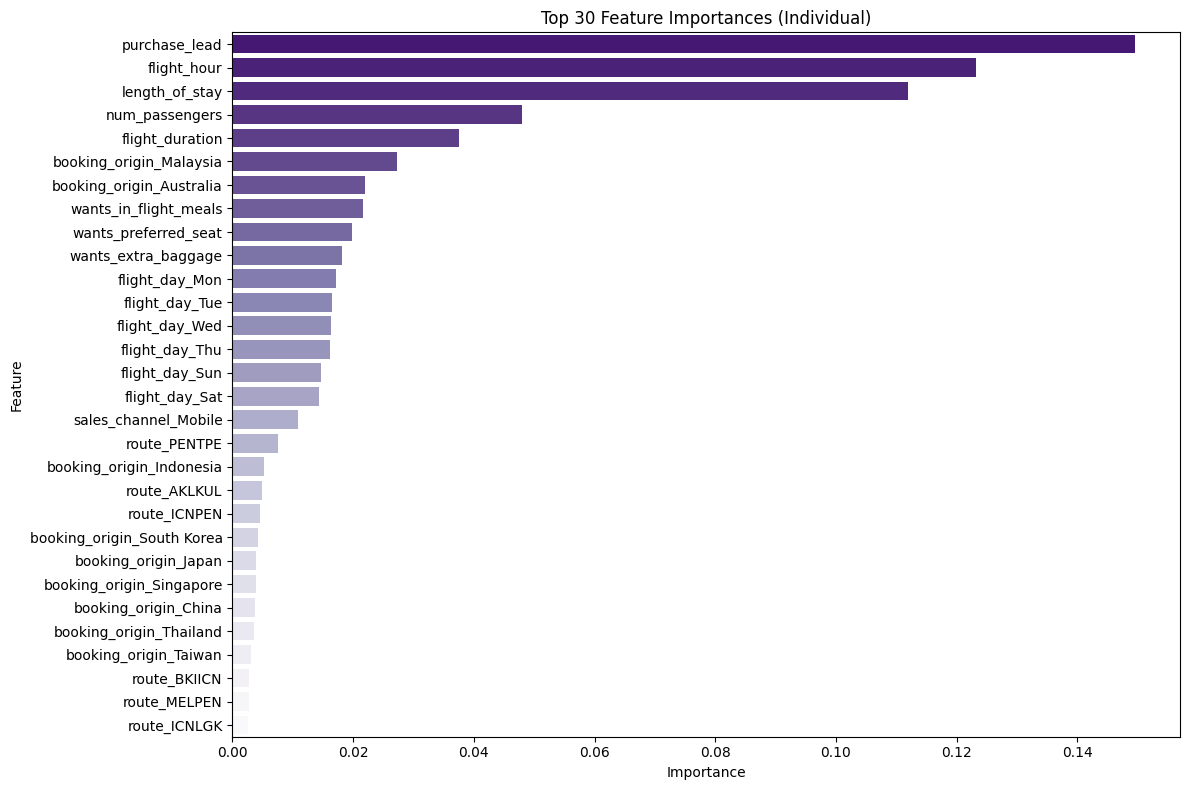

/tmp/ipykernel_120/503675320.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='base_feature', data=grouped_importances.head(20), palette='Blues_d')


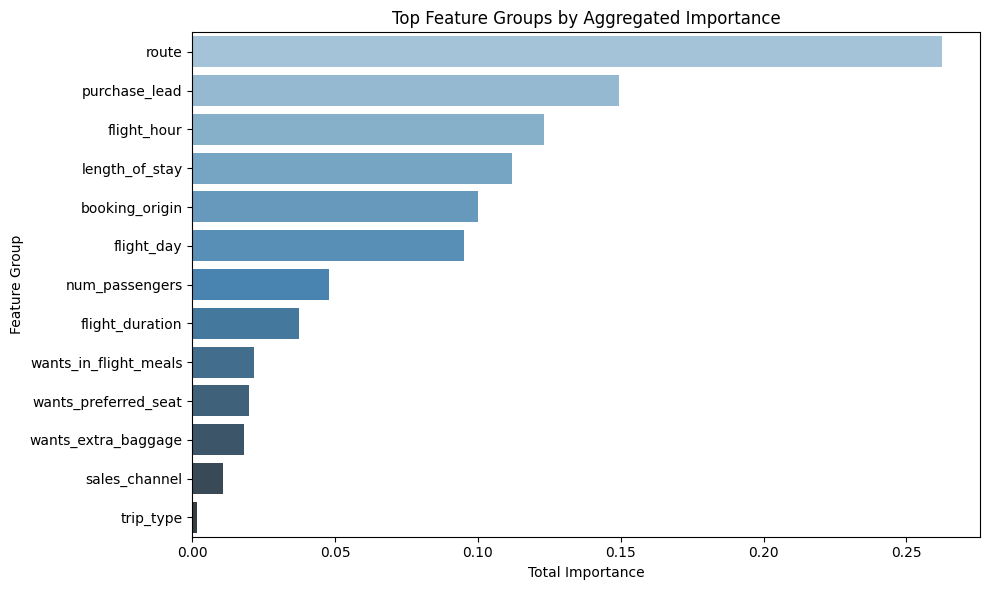

In [20]:
# Get feature importances from trained Random Forest model
importances = rf_model.feature_importances_
feature_importances = pd.DataFrame({'feature': X_train.columns, 'importance': importances})

# Sort individual feature importances
feature_importances = feature_importances.sort_values('importance', ascending=False)

# --- Step 1: Plot Top 30 Individual Features ---
plt.figure(figsize=(12, 8))
sns.barplot(x='importance', y='feature', data=feature_importances.head(30), palette='Purples_r')
plt.title('Top 30 Feature Importances (Individual)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# --- Step 2: Group by Base Feature Name ---
# Uses base_feature() from the cell above, so every route_* dummy is summed into 'route' (the old regex left
# each route as its own bar) and booking_origin_* into 'booking_origin'
feature_importances['base_feature'] = feature_importances['feature'].apply(base_feature)

grouped_importances = feature_importances.groupby('base_feature')['importance'].sum().reset_index()
grouped_importances = grouped_importances.sort_values('importance', ascending=False)

# --- Step 3: Plot Grouped Feature Importances ---
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='base_feature', data=grouped_importances.head(20), palette='Blues_d')
plt.title('Top Feature Groups by Aggregated Importance')
plt.xlabel('Total Importance')
plt.ylabel('Feature Group')
plt.tight_layout()
plt.show()

### Permutation importance (held-out data)
The built-in `feature_importances_` above are measured on the training data and favour continuous and many-valued columns. Shuffling a feature on the **test** set and measuring the drop in AUC-ROC is a more direct check of what the model actually relies on.

Test AUC-ROC: 0.7876
              feature  auc_drop     sd
       booking_origin    0.1472 0.0002
                route    0.0556 0.0008
       length_of_stay    0.0168 0.0012
      flight_duration    0.0090 0.0011
 wants_preferred_seat    0.0083 0.0004
        purchase_lead    0.0077 0.0013
        sales_channel    0.0076 0.0019
  wants_extra_baggage    0.0062 0.0009
          flight_hour    0.0046 0.0018
           flight_day    0.0045 0.0041
wants_in_flight_meals    0.0027 0.0012
            trip_type    0.0004 0.0001
       num_passengers   -0.0004 0.0011


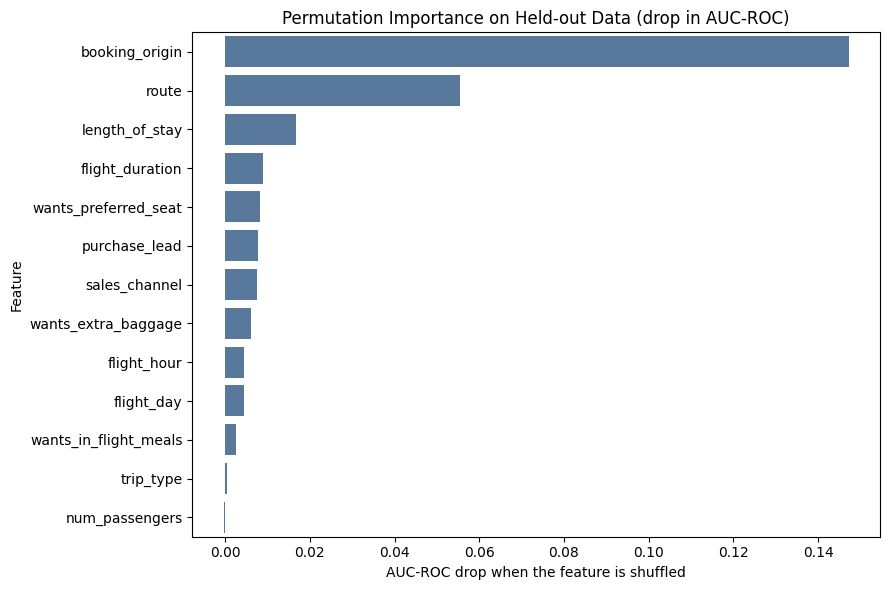

In [21]:
# Permutation importance on the held-out test set: shuffle all the dummy columns that belong to one original
# feature together, and record how much AUC-ROC drops. A big drop means the model relies on that feature.
base_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])
groups = {}
for col in X_test.columns:
    groups.setdefault(base_feature(col), []).append(col)

rng = np.random.default_rng(42)
rows = []
for feat, cols in groups.items():
    drops = []
    for _ in range(3):
        X_perm = X_test.copy()
        shuffled = rng.permutation(len(X_perm))
        X_perm[cols] = X_test[cols].values[shuffled]
        drops.append(base_auc - roc_auc_score(y_test, rf_model.predict_proba(X_perm)[:, 1]))
    rows.append((feat, np.mean(drops), np.std(drops)))

perm_importance = pd.DataFrame(rows, columns=['feature', 'auc_drop', 'sd']).sort_values('auc_drop', ascending=False)
print(f"Test AUC-ROC: {base_auc:.4f}")
print(perm_importance.round(4).to_string(index=False))

plt.figure(figsize=(9, 6))
sns.barplot(x='auc_drop', y='feature', data=perm_importance, color='#4c78a8')
plt.title('Permutation Importance on Held-out Data (drop in AUC-ROC)')
plt.xlabel('AUC-ROC drop when the feature is shuffled')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Reading the importances
The two methods disagree, and the held-out check is the one to trust. Grouped by original feature, the built-in importance puts route first (0.26), then purchase_lead (0.15), flight_hour (0.12), length_of_stay (0.11) and booking_origin (0.10): it spreads credit across many correlated dummies and favours continuous columns. When each feature is shuffled on the test set, booking_origin is by far the most important (AUC drops by 0.147), then route (0.056) and length_of_stay (0.017). purchase_lead (0.008) and flight_hour (0.005) matter little, and num_passengers adds nothing measurable. Booking origin and route carry related information, so their separate shares should not be over-interpreted.

### Direction of effects
Importance says how much a feature matters, not which way it pushes. Completion rate by bucket gives the direction.

In [22]:
bins = {'purchase_lead': [-1, 7, 21, 45, 90, 180, 900],
        'length_of_stay': [-1, 3, 7, 14, 28, 60, 800],
        'flight_hour': [-1, 5, 11, 17, 23]}
for c, b in bins.items():
    print(df.groupby(pd.cut(df[c], b))['booking_complete'].agg(['mean', 'size']).round(3), "\n")
for c in ['sales_channel', 'wants_extra_baggage', 'wants_preferred_seat']:
    print(df.groupby(c)['booking_complete'].agg(['mean', 'size']).round(3), "\n")
print(df.groupby('booking_origin')['booking_complete'].agg(['mean', 'size']).query('size >= 1500').sort_values('mean').round(3))

                mean   size
purchase_lead              
(-1, 7]        0.173   4813
(7, 21]        0.171   7912
(21, 45]       0.146  10256
(45, 90]       0.144  11173
(90, 180]      0.134   8627
(180, 900]     0.142   7219 

                 mean   size
length_of_stay              
(-1, 3]         0.178   3975
(3, 7]          0.194  20698
(14, 28]        0.101  12995
(28, 60]        0.101   8222
(60, 800]       0.146   4110 



              mean   size
flight_hour              
(-1, 5]      0.144  14619
(5, 11]      0.146  18668
(11, 17]     0.167  13749
(17, 23]     0.118   2964 

                mean   size
sales_channel              
Internet       0.155  44382
Mobile         0.108   5618 

                      mean   size
wants_extra_baggage              
0                    0.115  16561
1                    0.167  33439 

                       mean   size
wants_preferred_seat              
0                     0.138  35152
1                     0.177  14848 

                 mean   size
booking_origin              
Australia       0.050  17872
South Korea     0.101   4559
Taiwan          0.108   2077
Japan           0.123   3885
China           0.205   3387
Thailand        0.232   2030
Indonesia       0.260   2369
Malaysia        0.344   7174


### Reading the direction of effects
- **booking_origin:** completion ranges from 5.0% for Australia to 34.4% for Malaysia (Indonesia 26.0%, Thailand 23.2%).
- **purchase_lead:** shorter lead times convert slightly better (about 17% at 21 days or fewer, versus 13-14% beyond 90 days), the opposite of "booking further in advance means more likely to complete".
- **length_of_stay:** stays of 7 days or less convert at about 18-19%, versus about 10% for 14 to 60 days.
- **sales_channel:** Mobile converts at 10.8% versus 15.5% on the internet channel (not controlled for market mix).
- **Add-on flags:** extra baggage and preferred seats go with higher completion (16.7% vs 11.5%, and 17.7% vs 13.8%), but they are chosen inside the booking flow, so they are correlates rather than levers.

These effects are small next to booking origin.

## Cross-Validation

In [104]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report,precision_score

# Define target and features
target = "booking_complete"
features = [
    "purchase_lead", "num_passengers", "flight_hour", "flight_day", "trip_type",
    "route", "sales_channel", "length_of_stay", "flight_duration",
    "booking_origin", "wants_extra_baggage", "wants_preferred_seat",
    "wants_in_flight_meals"
]

X = df[features]
y = df[target]

# One-hot encode categorical variables
categorical_vars = ["flight_day", "trip_type", "route", "sales_channel", "booking_origin"]
X = pd.get_dummies(X, columns=categorical_vars, drop_first=True)

# Initialize model
clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=10,
    class_weight="balanced",  # boost recall for class 1
    random_state=42,
    n_jobs=-1
)
# 4. Model
model = RandomForestClassifier(n_estimators=200, random_state=42)

# Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_proba)
    auc_scores.append(auc)

    print(f"\nFold {fold} - Classification Report:")
    print(classification_report(y_test, y_pred))

# Summary
print(f"\nMean AUC-ROC Score: {np.mean(auc_scores):.2f}")


Fold 1 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.66      0.77      8505
           1       0.28      0.74      0.40      1495

    accuracy                           0.67     10000
   macro avg       0.61      0.70      0.59     10000
weighted avg       0.84      0.67      0.72     10000


Fold 2 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.65      0.77      8505
           1       0.28      0.78      0.42      1495

    accuracy                           0.67     10000
   macro avg       0.61      0.72      0.59     10000
weighted avg       0.85      0.67      0.72     10000


Fold 3 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.63      0.76      8504
           1       0.27      0.79      0.41      1496

    accuracy                           0.66     10000
   macro avg       0.61      

## The precision is low on predicting completed booking since the dataset itself is imbalanced, in which booking not complete has over 42000 records versus booking complete with 7478 records.  

## The model's purpose is not to make a final decision, but to serve as a triage tool. With high recall, it helps us identify a smaller, more manageable group of customers from the general population who are most likely to complete their booking. This allows our marketing and sales teams to allocate their resources more effectively, focusing their efforts on this narrowed-down list instead of the entire customer base.

### Hypertuning

#### Since the AUC-ROC score is between 0.76 and 0.78 — above the baseline of 0.5 — the model does effectively distinguish between completed and abandoned bookings.

#### Using only one feature (like purchase_lead) may give a high accuracy, but it oversimplifies the problem and risks overfitting. By including multiple features and tuning the model with cross-validation, we build a more balanced and generalizable model. This process helps ensure that the model performs well not just on the current data, but also on new, unseen cases—making it more reliable for real-world use.

In [105]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid for hypertuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [12, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'class_weight': ['balanced', {0:1, 1:5}, {0:1, 1:10}]
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    print(f"\n Fold {fold} hypertuning")

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    base_model = RandomForestClassifier(random_state=42, n_jobs=-1)
    
    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    y_pred = best_model.predict(X_test)
    print(f"Best params for fold {fold}: {grid_search.best_params_}")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=4))


 Fold 1 hypertuning
Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best params for fold 1: {'class_weight': {0: 1, 1: 5}, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}
[[6336 2169]
 [ 519  976]]
              precision    recall  f1-score   support

           0     0.9243    0.7450    0.8250      8505
           1     0.3103    0.6528    0.4207      1495

    accuracy                         0.7312     10000
   macro avg     0.6173    0.6989    0.6228     10000
weighted avg     0.8325    0.7312    0.7646     10000


 Fold 2 hypertuning
Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best params for fold 2: {'class_weight': {0: 1, 1: 5}, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 300}
[[6331 2174]
 [ 478 1017]]
              precision    recall  f1-score   support

           0     0.9298    0.7444    0.8268      8505
           1     0.3187    0.6803    0.4341      1495

    acc

# Summary of Findings – British Airways Booking Completion Analysis
### Using a Random Forest model tuned through Stratified K-Fold Cross-Validation to handle imbalanced data, the top factors influencing whether a customer completes a booking were:

- **Purchase Lead**: (how early the booking is made) - most influential
- **Flight Hour**: (time of flight)
- **Length of Stay**: (duration of trip)
- **Number of Passengers**: (size of group)
- **Booking Origin**: (specific countries stood out)

Customers who booked further in advance, selected earlier flight hours, and had longer stays or more passengers were significantly more likely to complete their bookings.

Model AUC-ROC score (0.78) suggests the model can effectively prioritize leads and be used as a triage tool by the marketing team.

#  Business Recommendation

Since purchase_lead is the strongest predictor, British Airways should:

Identify early planners (e.g., 40+ days in advance) and proactively engage them with:

Reminders to complete bookings

Loyalty incentives or personalized offers

Bundled upsells: Offer travel insurance, preferred seats, or meals at a discount to lock in commitment early

Travel insurance or extras like seats/meals to increase commitment

Additionally, flights with early departure hours and longer trip durations show higher conversion. These can be featured more prominently in marketing and search results.

The sales_channel_Mobile feature appears among the top predictors, suggesting platform choice may influence conversions, perhaps to look into streamlining UX and set up checkout reminders. 
Lastly, by combining behavioral insights with country-level booking patterns, targeted regional campaigns can be launched in high-performing markets (e.g., Malaysia showed significance in the model).
